In [51]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import random_split
from torch.utils.data import Subset
import matplotlib.pyplot as plt
from collections import Counter
import torch
import torch.nn as nn
from torch.utils.data import DataLoader


In [58]:
def exclude_digits(dataset, excluded_digits):
    indices = []

    for i in range(len(dataset)):
        image, label = dataset[i]

        if label not in excluded_digits:
            indices.append(i)

    return Subset(dataset, indices)

def plot_distribution(dataset, title):
    # 提取数据集中的所有标签
    labels = [int(dataset[i][1]) for i in range(len(dataset))]

    # 统计每个数字出现的次数
    counts = Counter(labels)

    # MNIST 包含数字 0～9
    digits = list(range(10))
    frequencies = [counts.get(d, 0) for d in digits]

    # 绘制柱状图
    plt.figure(figsize=(8, 4))
    plt.bar(digits, frequencies)

    plt.xlabel("Digit")
    plt.ylabel("Number of Samples")
    plt.title(title)
    plt.xticks(digits)
    plt.show()

class SimpleModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)

def train_model(model, dataset, epochs=1):
    # 创建数据加载器
    loader = DataLoader(
        dataset,
        batch_size=64,
        shuffle=True
    )

    # 损失函数
    criterion = nn.CrossEntropyLoss()

    # 优化器
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=0.01
    )
     # 开始训练
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for images, labels in loader:
            # 前向传播
            outputs = model(images)

            # 计算损失
            loss = criterion(outputs, labels)

            # 清除旧梯度
            optimizer.zero_grad()

            # 反向传播
            loss.backward()

            # 更新参数
            optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {epoch+1}, Loss: {total_loss/len(loader):.4f}")

    return model



def include_digits(dataset, included_digits):
    indices = []

    for i in range(len(dataset)):
        image, label = dataset[i]

        if label in included_digits:
            indices.append(i)

    return Subset(dataset, indices)

import torch
from torch.utils.data import DataLoader


def evaluate_model(model, testset):
    # 1. 加载测试数据
    testloader = DataLoader(
        testset,
        batch_size=64,
        shuffle=False
    )

    # 2. 切换到评估模式
    model.eval()

    correct = 0
    total = 0

    # 3. 测试时不计算梯度
    with torch.no_grad():

        for images, labels in testloader:

            # 前向传播
            outputs = model(images)

            # 获取预测类别
            predictions = torch.argmax(outputs, dim=1)

            # 统计预测正确的数量
            correct += (predictions == labels).sum().item()

            # 统计总样本数量
            total += labels.size(0)

    # 4. 计算准确率
    accuracy = 100 * correct / total

    return accuracy

In [31]:
trainset=datasets.MNIST(
    "../MNIST_data", download=True, train=True, transform=transforms.ToTensor()
)

In [54]:
testset=datasets.MNIST(
    "../MNIST_data", download=True, train=False, transform=transforms.ToTensor()
)

In [37]:
total_length=len(trainset)
split_size=total_length//3
torch.manual_seed(42)
part1,part2,part3=random_split(trainset,[split_size]*3)

In [38]:
part1=exclude_digits(part1,excluded_digits=[1,3,7])
part2=exclude_digits(part2,excluded_digits=[2,5,8])
part3=exclude_digits(part3,excluded_digits=[4,6,9])


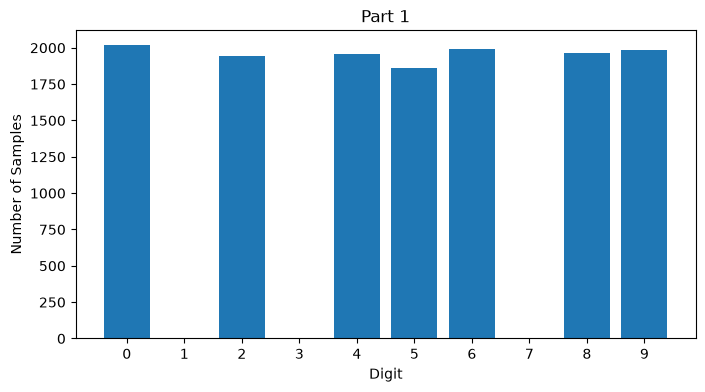

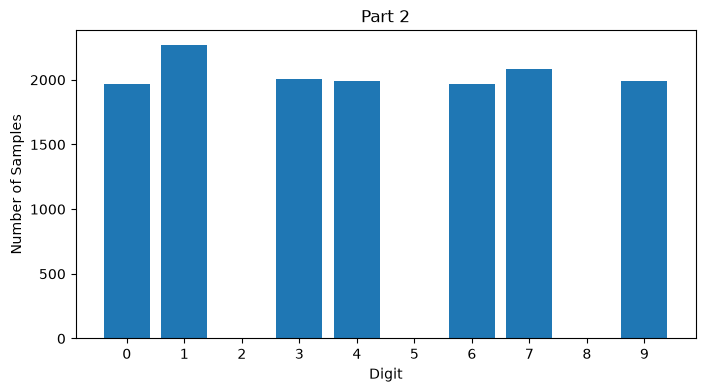

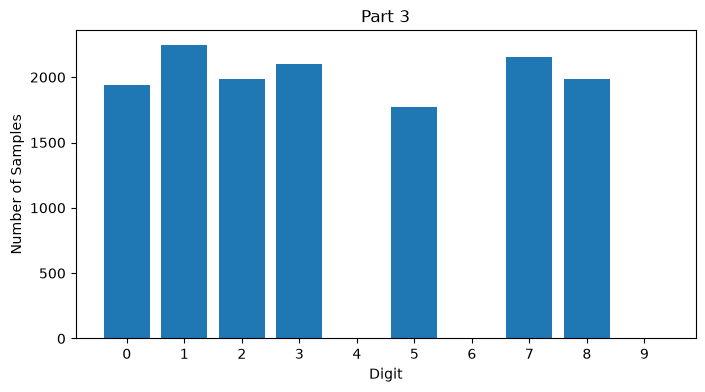

In [39]:
plot_distribution(part1,"Part 1")
plot_distribution(part2,"Part 2")
plot_distribution(part3,"Part 3")

In [45]:
model1=SimpleModel()
train_model(model1,part1,epochs=5)
model2=SimpleModel()
train_model(model2,part2,epochs=5)
model3=SimpleModel()
train_model(model3,part3,epochs=5)

Epoch 1, Loss: 1.7927
Epoch 2, Loss: 0.9922
Epoch 3, Loss: 0.6301
Epoch 4, Loss: 0.4860
Epoch 5, Loss: 0.4114
Epoch 1, Loss: 1.7339
Epoch 2, Loss: 0.7808
Epoch 3, Loss: 0.4692
Epoch 4, Loss: 0.3591
Epoch 5, Loss: 0.3036
Epoch 1, Loss: 1.7792
Epoch 2, Loss: 0.9289
Epoch 3, Loss: 0.5991
Epoch 4, Loss: 0.4721
Epoch 5, Loss: 0.4088


SimpleModel(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [55]:
testset_137=include_digits(testset,included_digits=[1,3,7])
testset_258=include_digits(testset,included_digits=[2,5,8])
testset_469=include_digits(testset,included_digits=[4,6,9])

In [60]:
accuracy1=evaluate_model(model1,testset)
accuracy_on_137=evaluate_model(model1,testset_137)
print(
    f"Model 1 Accuracy on Full Test Set: {accuracy1:.2f},"
    f"Accuracy on 1,3,7: {accuracy_on_137:.2f}"
)
accuracy2=evaluate_model(model2,testset)
accuracy_on_258=evaluate_model(model2,testset_258)
print(
    f"Model 2 Accuracy on Full Test Set: {accuracy2:.2f},"
    f"Accuracy on 2,5,8: {accuracy_on_258:.2f}"
)
accuracy3=evaluate_model(model3,testset)
accuracy_on_469=evaluate_model(model3,testset_469)
print(
    f"Model 3 Accuracy on Full Test Set: {accuracy3:.2f},"
    f"Accuracy on 4,6,9: {accuracy_on_469:.2f}"
)


Model 1 Accuracy on Full Test Set: 61.34,Accuracy on 1,3,7: 0.00
Model 2 Accuracy on Full Test Set: 66.35,Accuracy on 2,5,8: 0.00
Model 3 Accuracy on Full Test Set: 63.66,Accuracy on 4,6,9: 0.00
